<a href="https://colab.research.google.com/github/lakshlahoti15/MDS_LAB/blob/main/MDS_WEEK_12%2C13%2614.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
sns.set_theme(style="whitegrid")

In [18]:
house = pd.read_csv('/content/house_prices (1).csv')

In [19]:
house.columns.tolist()

['id',
 'date',
 'price',
 'bedrooms',
 'bathrooms',
 'sqft_living',
 'sqft_lot',
 'floors',
 'waterfront',
 'view',
 'condition',
 'grade',
 'sqft_above',
 'sqft_basement',
 'yr_built',
 'yr_renovated',
 'zipcode',
 'lat',
 'long',
 'sqft_living15',
 'sqft_lot15']

In [20]:
house['date'] = pd.to_datetime(house['date'])
yearly_price = house.groupby(
    house['date'].dt.year
)['price'].mean()

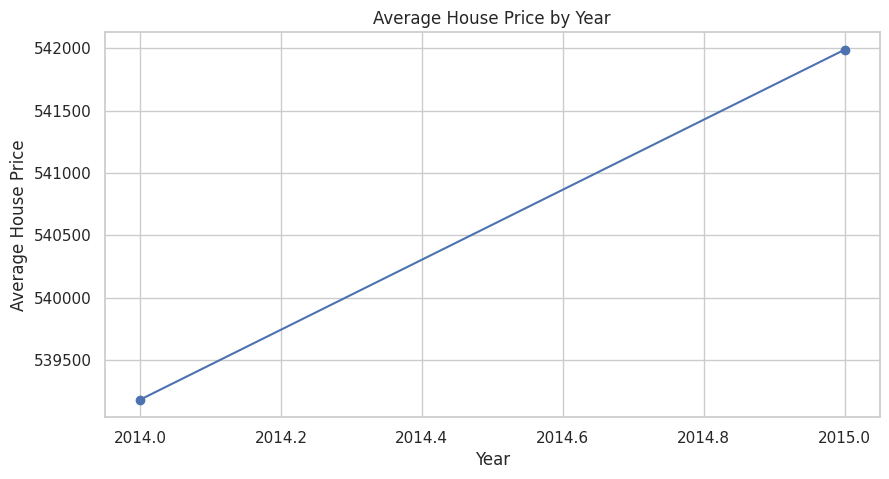

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_price.index,
    yearly_price.values,
    marker='o'
)

plt.xlabel('Year')
plt.ylabel('Average House Price')
plt.title('Average House Price by Year')

plt.show()

In [22]:
bedroom_price = house.groupby(
    'bedrooms'
)['price'].mean()

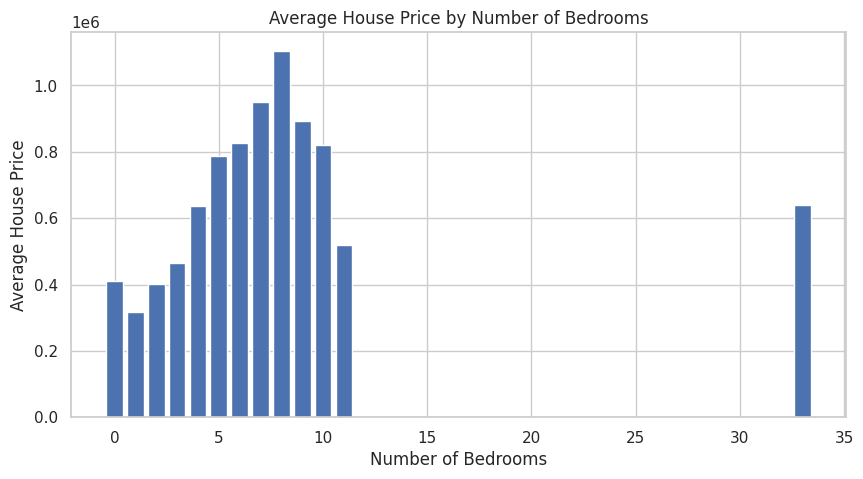

In [23]:
plt.figure(figsize=(10, 5))

plt.bar(
    bedroom_price.index,
    bedroom_price.values
)

plt.xlabel('Number of Bedrooms')
plt.ylabel('Average House Price')
plt.title('Average House Price by Number of Bedrooms')

plt.show()

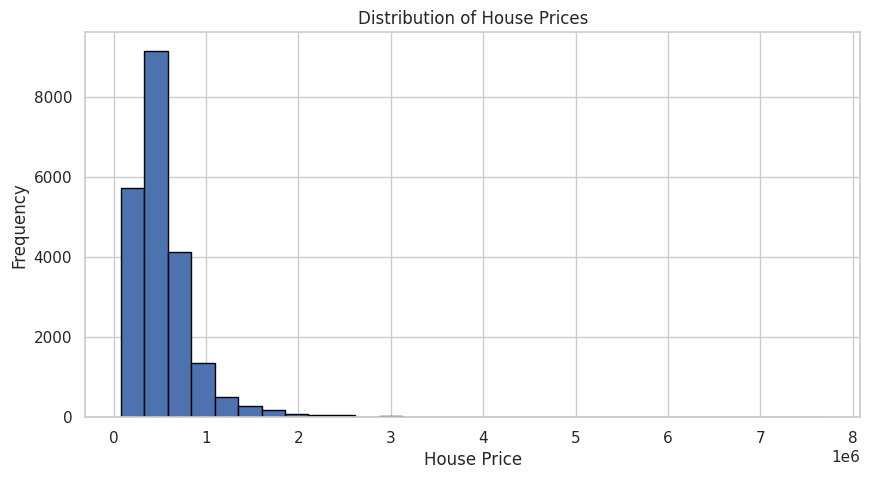

In [24]:
plt.figure(figsize=(10, 5))

plt.hist(
    house['price'],
    bins=30,
    edgecolor='black'
)

plt.xlabel('House Price')
plt.ylabel('Frequency')
plt.title('Distribution of House Prices')

plt.show()

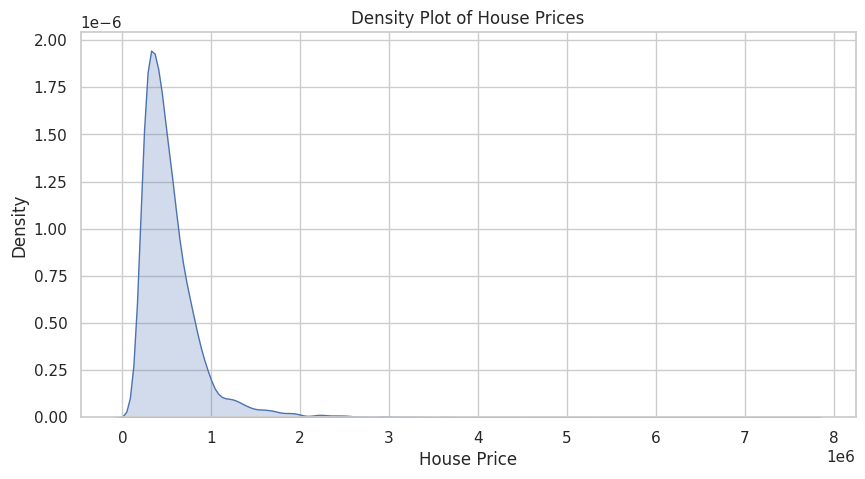

In [25]:
plt.figure(figsize=(10, 5))

sns.kdeplot(
    house['price'],
    fill=True
)

plt.xlabel('House Price')
plt.ylabel('Density')
plt.title('Density Plot of House Prices')

plt.show()

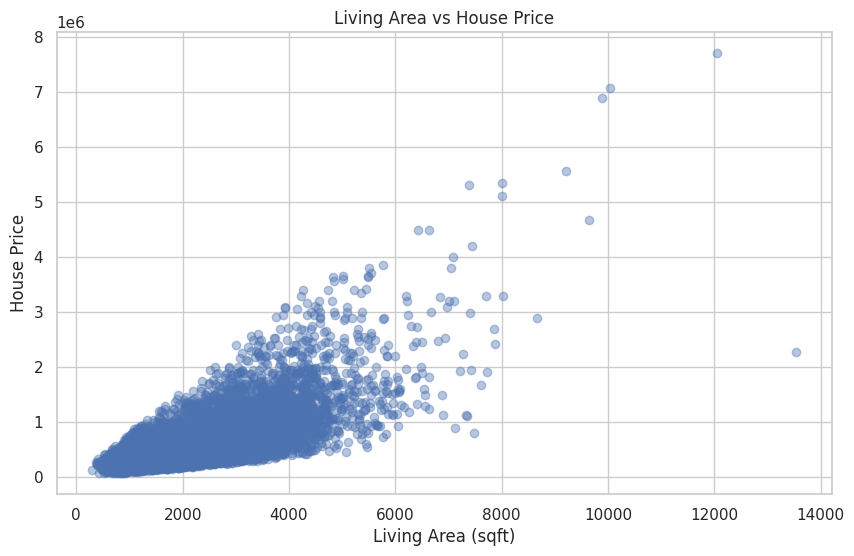

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    house['sqft_living'],
    house['price'],
    alpha=0.4
)

plt.xlabel('Living Area (sqft)')
plt.ylabel('House Price')
plt.title('Living Area vs House Price')

plt.show()

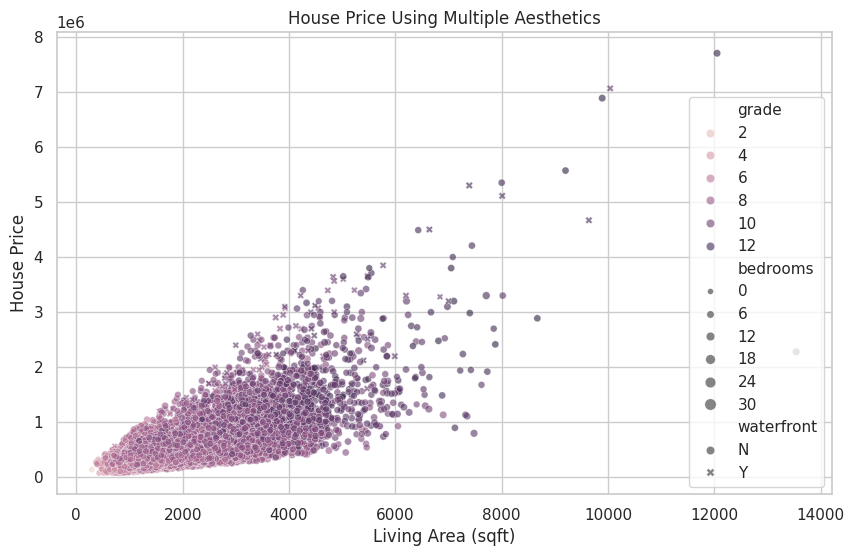

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=house,
    x='sqft_living',
    y='price',
    hue='grade',
    size='bedrooms',
    style='waterfront',
    alpha=0.6
)

plt.title('House Price Using Multiple Aesthetics')
plt.xlabel('Living Area (sqft)')
plt.ylabel('House Price')

plt.show()

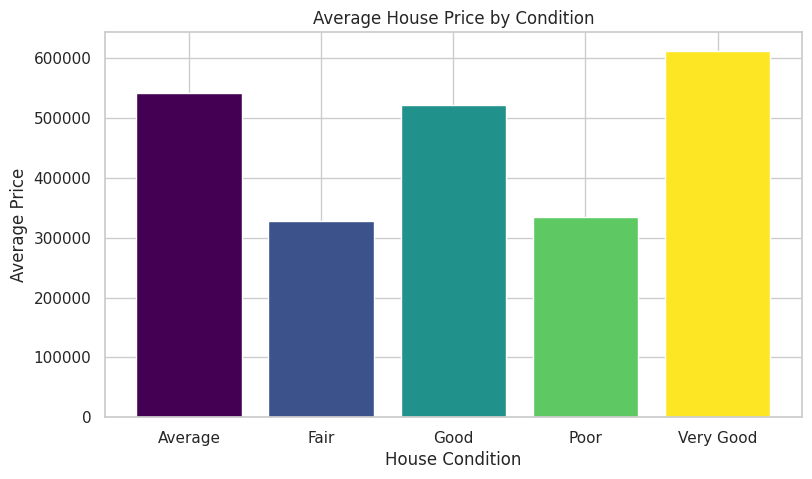

In [29]:
condition_price = house.groupby('condition')['price'].mean()

plt.figure(figsize=(9, 5))

plt.bar(
    condition_price.index,
    condition_price.values,
    color=plt.cm.viridis(
        np.linspace(0, 1, len(condition_price))
    )
)

plt.xlabel('House Condition')
plt.ylabel('Average Price')
plt.title('Average House Price by Condition')

plt.show()

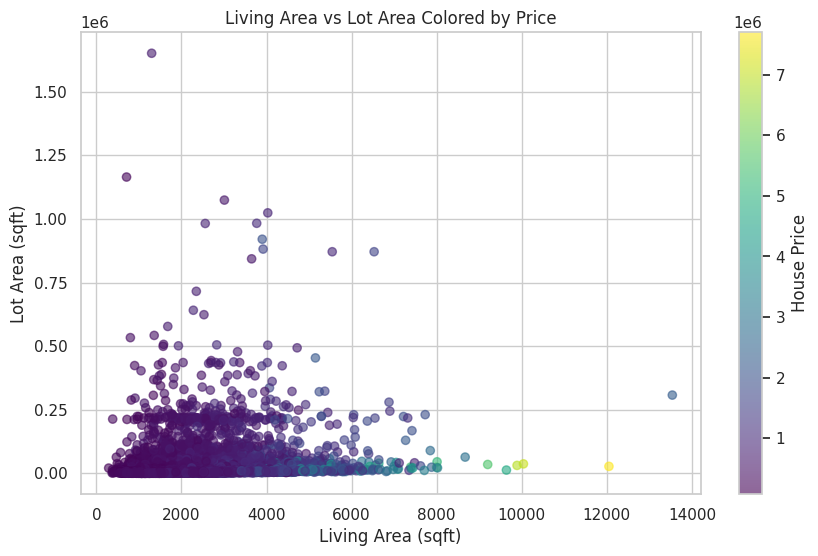

In [30]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    house['sqft_living'],
    house['sqft_lot'],
    c=house['price'],
    cmap='viridis',
    alpha=0.6
)

plt.xlabel('Living Area (sqft)')
plt.ylabel('Lot Area (sqft)')
plt.title('Living Area vs Lot Area Colored by Price')

plt.colorbar(scatter, label='House Price')

plt.show()

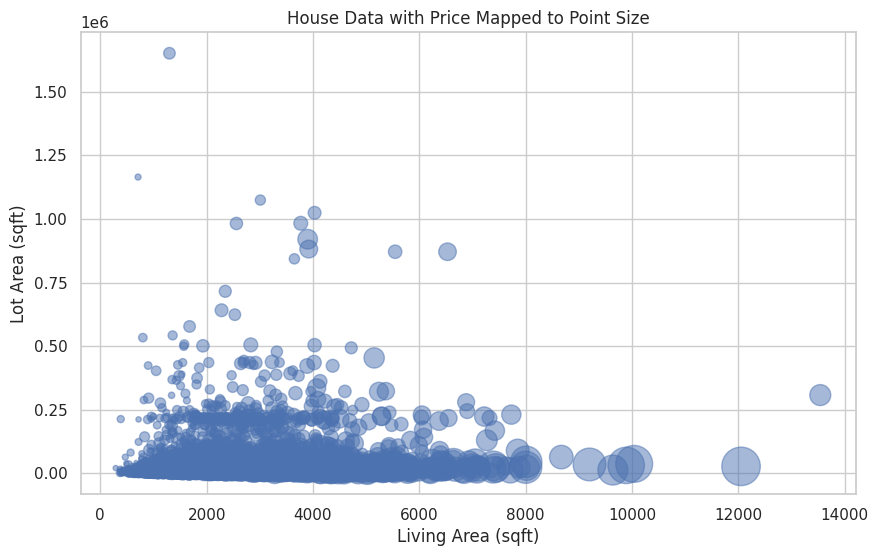

In [31]:
plt.figure(figsize=(10, 6))

plt.scatter(
    house['sqft_living'],
    house['sqft_lot'],
    s=house['price'] / 10000,
    alpha=0.5
)

plt.xlabel('Living Area (sqft)')
plt.ylabel('Lot Area (sqft)')
plt.title('House Data with Price Mapped to Point Size')

plt.show()

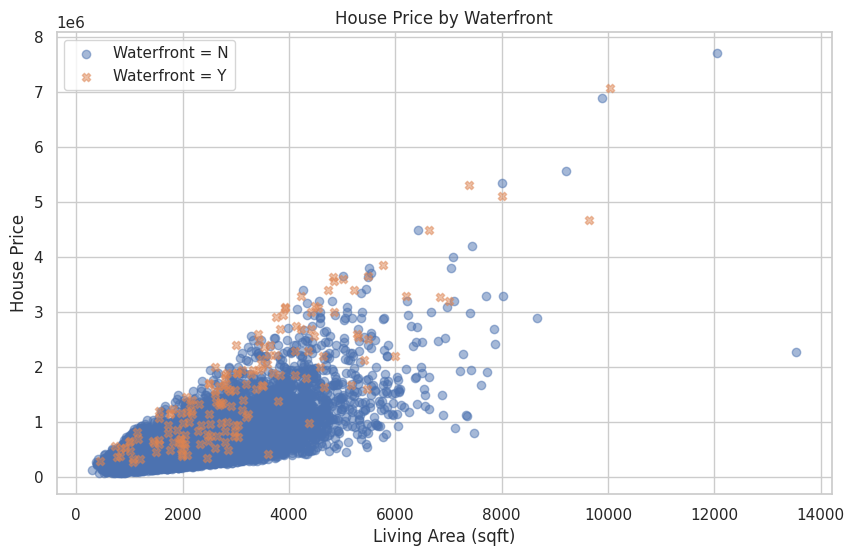

In [32]:
plt.figure(figsize=(10, 6))

for value, marker in [('N', 'o'), ('Y', 'X')]:
    data = house[house['waterfront'] == value]

    plt.scatter(
        data['sqft_living'],
        data['price'],
        marker=marker,
        alpha=0.5,
        label='Waterfront = ' + value
    )

plt.xlabel('Living Area (sqft)')
plt.ylabel('House Price')
plt.title('House Price by Waterfront')
plt.legend()

plt.show()

In [33]:
floor_price = house.groupby('floors')['price'].mean()

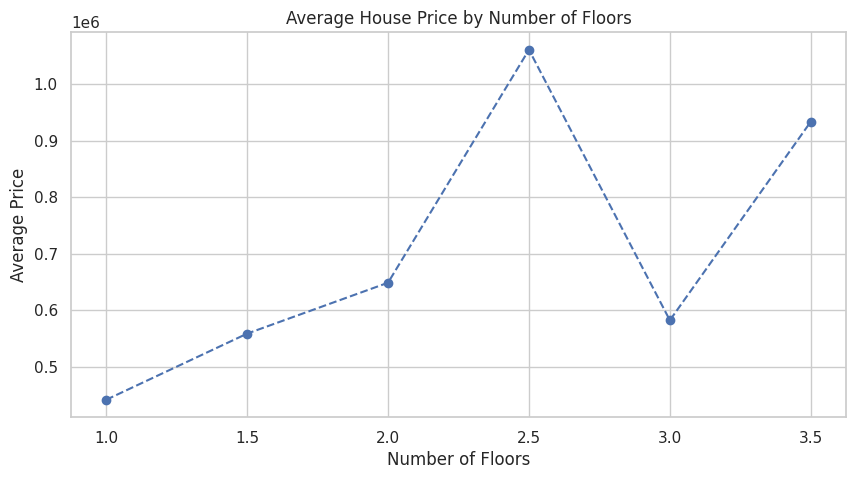

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    floor_price.index,
    floor_price.values,
    marker='o',
    linestyle='--'
)

plt.xlabel('Number of Floors')
plt.ylabel('Average Price')
plt.title('Average House Price by Number of Floors')

plt.show()

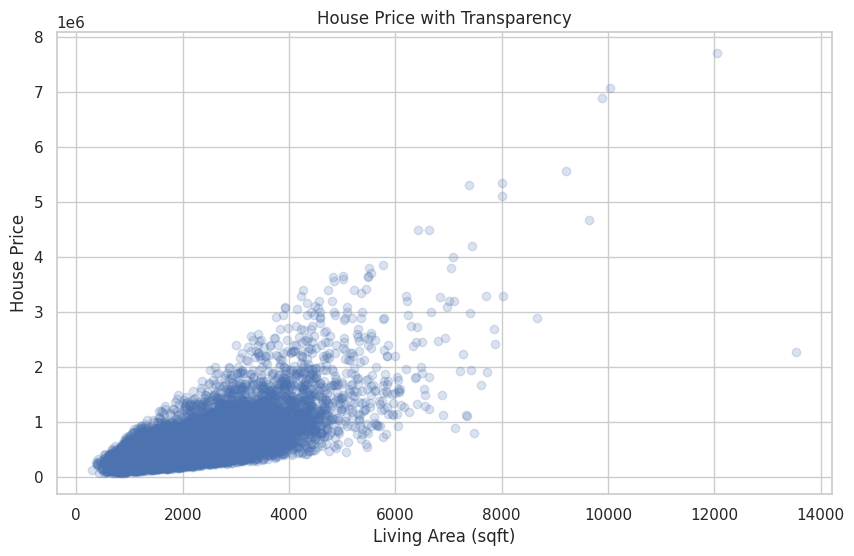

In [35]:
plt.figure(figsize=(10, 6))

plt.scatter(
    house['sqft_living'],
    house['price'],
    alpha=0.2
)

plt.xlabel('Living Area (sqft)')
plt.ylabel('House Price')
plt.title('House Price with Transparency')

plt.show()

In [37]:
from datasets import load_dataset

rain_dataset = load_dataset(
    "electricsheepafrica/africa-mli-rainfall-subnational"
)

rain = rain_dataset["train"].to_pandas()

rain.head()

,date,adm_level,adm_id,pcode,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version,esa_source,esa_processed
0,2016-09-21,2,19378,ML0103,763.0,21.099607,38.999737,131.238530,137.286290,573.441700,498.837220,59.317642,95.74958,114.80726,final,HDX,2026-04-05
1,1998-11-11,1,1927,ML07,6038.0,0.000000,0.000000,0.647731,0.734658,81.285540,61.537120,100.000000,98.48418,129.68028,final,HDX,2026-04-05
2,2004-01-11,2,19391,ML0205,397.0,0.000000,0.000000,0.000000,0.000000,10.657431,8.407724,100.000000,100.00000,116.77918,final,HDX,2026-04-05
3,2010-04-11,2,19383,ML0801,779.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,100.00000,100.00000,final,HDX,2026-04-05
4,2013-02-21,2,19402,ML0401,161.0,0.000000,0.000000,0.000000,0.000000,0.006211,0.024638,100.000000,100.00000,99.63328,final,HDX,2026-04-05


In [38]:
rain.shape

(76936, 17)

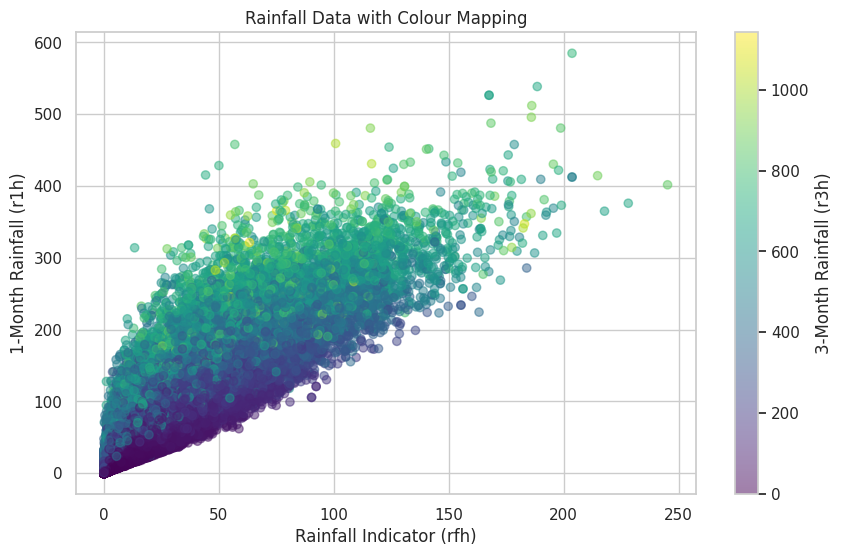

In [39]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rain['rfh'],
    rain['r1h'],
    c=rain['r3h'],
    cmap='viridis',
    alpha=0.5
)

plt.xlabel('Rainfall Indicator (rfh)')
plt.ylabel('1-Month Rainfall (r1h)')
plt.title('Rainfall Data with Colour Mapping')

plt.colorbar(scatter, label='3-Month Rainfall (r3h)')

plt.show()

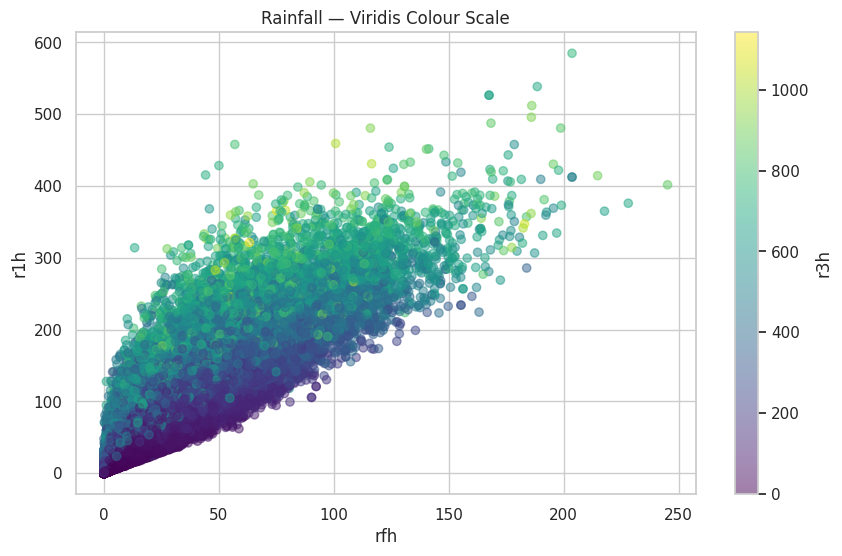

In [40]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rain['rfh'],
    rain['r1h'],
    c=rain['r3h'],
    cmap='viridis',
    alpha=0.5
)

plt.xlabel('rfh')
plt.ylabel('r1h')
plt.title('Rainfall — Viridis Colour Scale')

plt.colorbar(scatter, label='r3h')

plt.show()

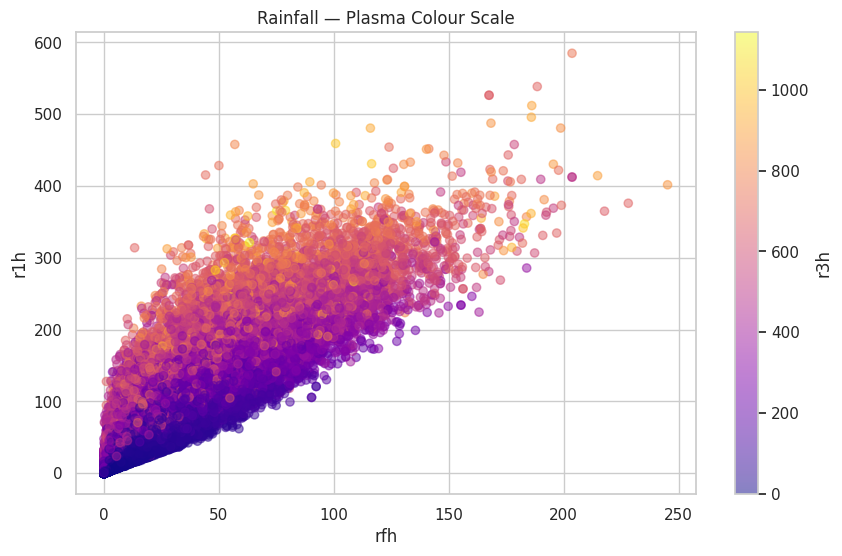

In [41]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rain['rfh'],
    rain['r1h'],
    c=rain['r3h'],
    cmap='plasma',
    alpha=0.5
)

plt.xlabel('rfh')
plt.ylabel('r1h')
plt.title('Rainfall — Plasma Colour Scale')

plt.colorbar(scatter, label='r3h')

plt.show()

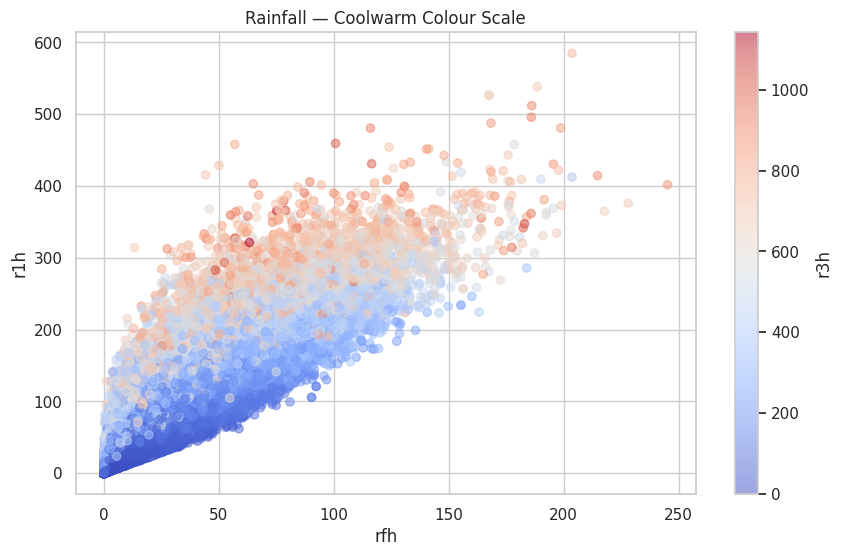

In [42]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rain['rfh'],
    rain['r1h'],
    c=rain['r3h'],
    cmap='coolwarm',
    alpha=0.5
)

plt.xlabel('rfh')
plt.ylabel('r1h')
plt.title('Rainfall — Coolwarm Colour Scale')

plt.colorbar(scatter, label='r3h')

plt.show()

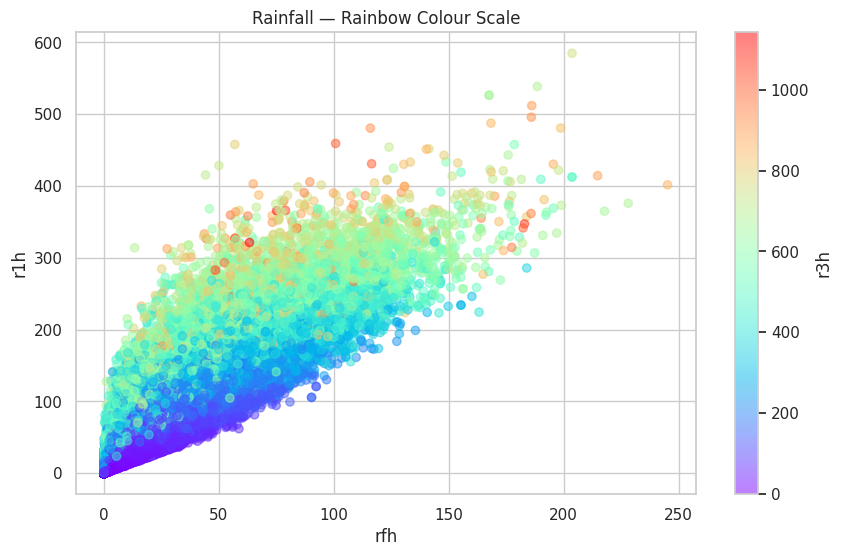

In [43]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rain['rfh'],
    rain['r1h'],
    c=rain['r3h'],
    cmap='rainbow',
    alpha=0.5
)

plt.xlabel('rfh')
plt.ylabel('r1h')
plt.title('Rainfall — Rainbow Colour Scale')

plt.colorbar(scatter, label='r3h')

plt.show()